### Standardization

Standardization is a feature-scaling technique that transforms numerical features so they have a mean of approximately 0 and a standard deviation of approximately 1. It changes the scale of the features, but does not change the order of the values.

In this notebook, we apply standardization to the **Age** and **EstimatedSalary** columns from the Social Network Ads dataset. We use Scikit-learn's `StandardScaler`, compare model performance before and after scaling, observe the effect of outliers, and implement standardization with a custom Python class.

**How Standardization Works**

Standardization transforms each feature using:

$$z = \frac{x - \mu}{\sigma}$$

Where:
- $x$ is the original feature value.
- $\mu$ is the mean of that feature in the training data.
- $\sigma$ is the standard deviation of that feature in the training data.
- $z$ is the standardized value.

After transformation, each feature has a mean close to 0 and a standard deviation close to 1 on the data used to fit the scaler. Test data is transformed using the training mean and standard deviation; its mean and standard deviation are not guaranteed to be exactly 0 and 1.

In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

In [2]:
df = pd.read_csv('Datasets/Social_Network_Ads.csv')

In [3]:
df = df[['Age', 'EstimatedSalary', 'Purchased']]
df.sample(5)

,Age,EstimatedSalary,Purchased
241,38,59000,0
195,34,43000,0
160,32,100000,1
319,36,60000,0
309,38,50000,0


### Train Test Split 

We separate the input features (`X`) from the target (`y`) and split the dataset into training and testing sets.

**Important :** Split the data before scaling. Fit the scaler only on the training features, then use that same fitted scaler to transform both training and test features. This prevents information from the test set from influencing preprocessing.

In [4]:
X = df.drop(columns= 'Purchased')
X

,Age,EstimatedSalary
0,19,19000
1,35,20000
2,26,43000
3,27,57000
4,19,76000
...,...,...
395,46,41000
396,51,23000
397,50,20000
398,36,33000


In [5]:
y = df['Purchased']
y

0      0
1      0
2      0
3      0
4      0
      ..
395    1
396    1
397    1
398    0
399    1
Name: Purchased, Length: 400, dtype: int64

In [6]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=0) 

In [7]:
X_train.shape, X_test.shape

((320, 2), (80, 2))

### Standradization - Using Sklearn StandradScaler Class

In [8]:
from sklearn.preprocessing import StandardScaler

In [9]:
scaler = StandardScaler()

In [10]:
# fit the scaler to the train set , also caculate the mean and std 
scaler.fit(X_train)

StandardScaler()

In [11]:
scaler.mean_

array([3.8218750e+01, 6.9928125e+04])

In [12]:
scaler.scale_ # std 

array([1.02869285e+01, 3.45159993e+04])

In [13]:
# transfrom train and test sets 
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [14]:
X_train_scaled

array([[ 1.92295008e+00,  2.14601566e+00],
       [ 2.02016082e+00,  3.78719297e-01],
       [-1.38221530e+00, -4.32498705e-01],
       [-1.18779381e+00, -1.01194013e+00],
       [ 1.92295008e+00, -9.25023920e-01],
       [ 3.67578135e-01,  2.91803083e-01],
       [ 1.73156642e-01,  1.46942725e-01],
       [ 2.02016082e+00,  1.74040666e+00],
       [ 7.56421121e-01, -8.38107706e-01],
       [ 2.70367388e-01, -2.87638347e-01],
       [ 3.67578135e-01, -1.71750061e-01],
       [-1.18475597e-01,  2.20395980e+00],
       [-1.47942605e+00, -6.35303205e-01],
       [-1.28500455e+00, -1.06988428e+00],
       [-1.38221530e+00,  4.07691369e-01],
       [-1.09058306e+00,  7.55356227e-01],
       [-1.47942605e+00, -2.00722133e-01],
       [ 9.50842613e-01, -1.06988428e+00],
       [ 9.50842613e-01,  5.81523798e-01],
       [ 3.67578135e-01,  9.87132798e-01],
       [ 5.61999628e-01, -8.96051849e-01],
       [-6.04529329e-01,  1.45068594e+00],
       [-2.12648508e-02, -5.77359062e-01],
       [-6.

In [15]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

In [16]:
X_train_scaled

,Age,EstimatedSalary
0,1.922950,2.146016
1,2.020161,0.378719
2,-1.382215,-0.432499
3,-1.187794,-1.011940
4,1.922950,-0.925024
...,...,...
315,0.950843,-1.156800
316,-0.896162,-0.780164
317,-0.215686,-0.519415
318,-1.090583,-0.461471


In [17]:
np.round(X_train.describe(), 2)

,Age,EstimatedSalary
count,320.00,320.00
mean,38.22,69928.12
std,10.30,34570.06
min,18.00,15000.00
25%,30.00,43000.00
50%,38.00,69500.00
75%,46.00,88000.00
max,60.00,150000.00


In [18]:
np.round(X_train_scaled.describe(), 2)

,Age,EstimatedSalary
count,320.00,320.00
mean,0.00,0.00
std,1.00,1.00
min,-1.97,-1.59
25%,-0.80,-0.78
50%,-0.02,-0.01
75%,0.76,0.52
max,2.12,2.32


### Inspect the Scaled Data

The summary statistics and plots compare the original and standardized feature values. Standardization changes the scale and location of the values, but it does not change the number of rows, the number of columns, or the relative ordering of values within a feature.

**Here we see the shape of data is not change, only the scale chages.**

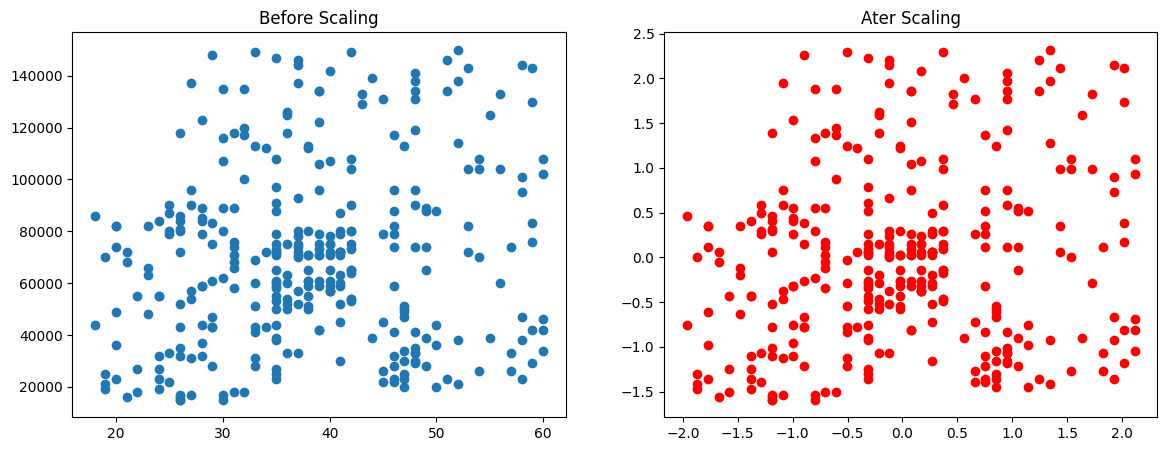

In [19]:
fig, ax = plt.subplots(ncols=2, figsize=(14,5))

ax[0].scatter(X_train['Age'], X_train['EstimatedSalary'])
ax[0].set_title('Before Scaling')

ax[1].scatter(X_train_scaled['Age'], X_train_scaled['EstimatedSalary'], color='red')
ax[1].set_title('Ater Scaling')

plt.show()

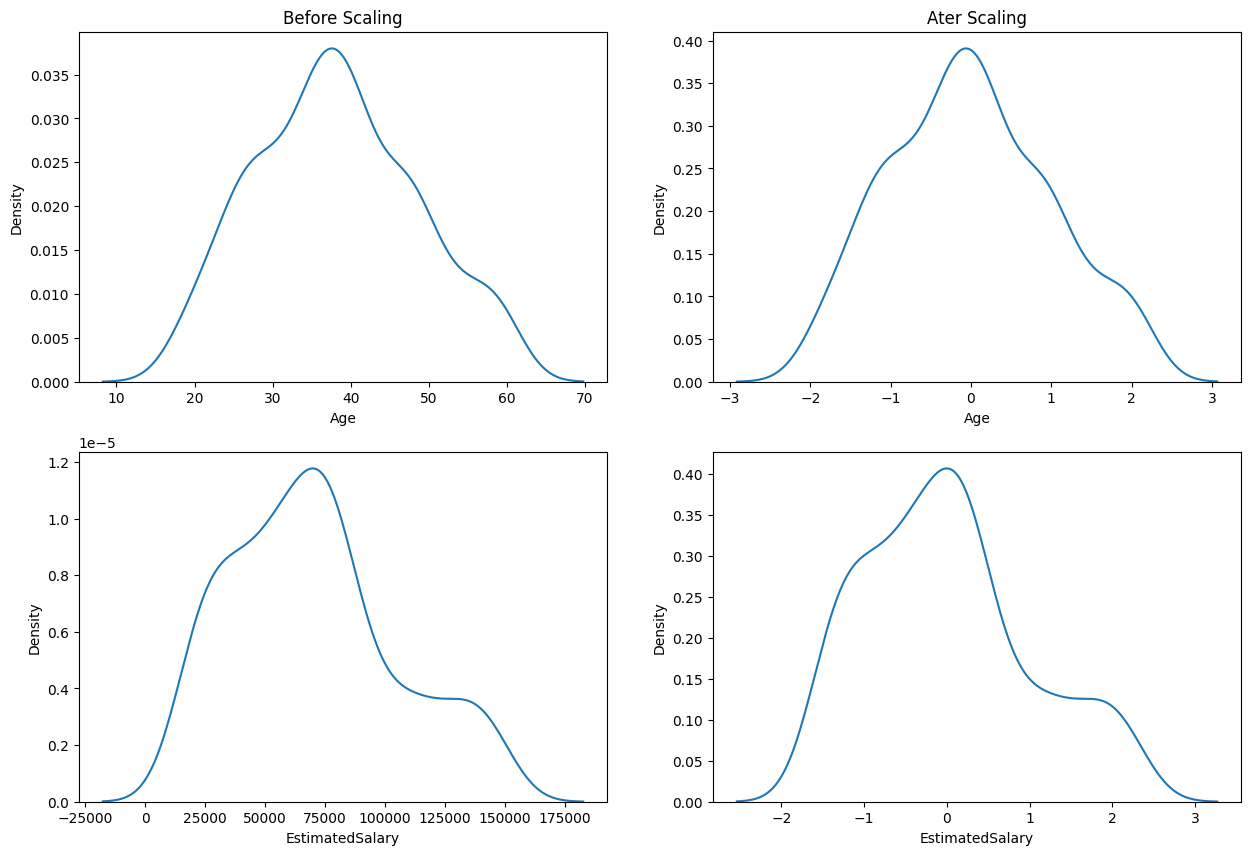

In [20]:
fig, ax = plt.subplots(ncols=2, nrows=2, figsize=(15,10))

# before scaling 
ax[0,0].set_title('Before Scaling')
sns.kdeplot(X_train['Age'], ax = ax[0,0])
sns.kdeplot(X_train['EstimatedSalary'], ax = ax[1,0])

# after scaling 
ax[0,1].set_title('Ater Scaling')
sns.kdeplot(X_train_scaled['Age'], ax = ax[0,1])
sns.kdeplot(X_train_scaled['EstimatedSalary'], ax = ax[1,1])

plt.show()

### Why Scaling is important ?

In [22]:
# Example 1 - Here Scaling is important
from sklearn.linear_model import LogisticRegression

In [23]:
lr = LogisticRegression()
lr_scaled = LogisticRegression() 

#### Compare Logistic Regression Before and After Scaling

Logistic Regression is affected by feature scale. When input features have very different ranges, optimization can be less effective and the model may not perform as well. Comparing the accuracy before and after standardization demonstrates why scaling can matter for this algorithm.

In [24]:
lr.fit(X_train, y_train)
lr_scaled.fit(X_train_scaled, y_train)

LogisticRegression()

In [25]:
y_pred = lr.predict(X_test)
y_pred_scaled = lr_scaled.predict(X_test_scaled)

In [26]:
from sklearn.metrics import accuracy_score

In [27]:
print("Actual : ", accuracy_score(y_test, y_pred))
print("Scaled : ", accuracy_score(y_test, y_pred_scaled))

Actual :  0.9125
Scaled :  0.925


#### Compare Decision Tree Before and After Scaling

Decision Trees generally do not require standardization. They make decisions using feature split thresholds, so changing the units or scale of a feature usually does not change the underlying split ordering. Small differences may still occur due to implementation details or ties.

In [28]:
# Example - 2 Here scaling is itni impotant nhi h 
from sklearn.tree import DecisionTreeClassifier

In [29]:
dt = DecisionTreeClassifier()
dt_scaled = DecisionTreeClassifier()

In [30]:
dt.fit(X_train,y_train)
dt_scaled.fit(X_train_scaled, y_train)

DecisionTreeClassifier()

In [31]:
y_pred = dt.predict(X_test)
y_pred_scaled = dt_scaled.predict(X_test_scaled)

In [32]:
print("Actual : ", accuracy_score(y_test, y_pred))
print("Scaled : ", accuracy_score(y_test, y_pred_scaled))

Actual :  0.9125
Scaled :  0.9125


### Effect of Outliers on Standardization

Standardization uses the mean and standard deviation, both of which are sensitive to extreme values. Outliers can shift the mean and increase the standard deviation, causing many ordinary observations to be compressed into a narrower range after scaling.

The following cells add a few extreme observations and visualize how they affect the feature distribution and standardized values.

In [33]:
# first add outliers 
outliers = pd.DataFrame({
    'Age' : [5, 90, 98],
    'EstimatedSalary' : [1000, 250000, 350000], 
    'Purchased' : [0,1,1]
})

In [34]:
df = pd.concat([df, outliers], ignore_index=True)

In [35]:
df

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0
...,...,...,...
398,36,33000,0
399,49,36000,1
400,5,1000,0
401,90,250000,1


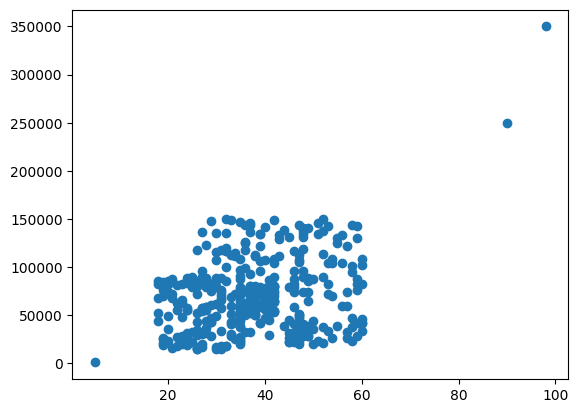

In [36]:
plt.scatter(df['Age'], df['EstimatedSalary'])

In [37]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(df.drop(columns= 'Purchased'),df['Purchased'], test_size=0.2, random_state=0) 

X_train.shape, X_test.shape

((322, 2), (81, 2))

In [38]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(X_train)

StandardScaler()

In [39]:
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [40]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

In [41]:
X_train_scaled

,Age,EstimatedSalary
0,-1.326403,0.405638
1,-0.217048,1.371685
2,1.262093,0.576117
3,1.909217,0.377225
4,-1.326403,-0.418344
...,...,...
317,0.892308,-1.128673
318,-0.864172,-0.759302
319,-0.217048,-0.503584
320,-1.049065,-0.446757


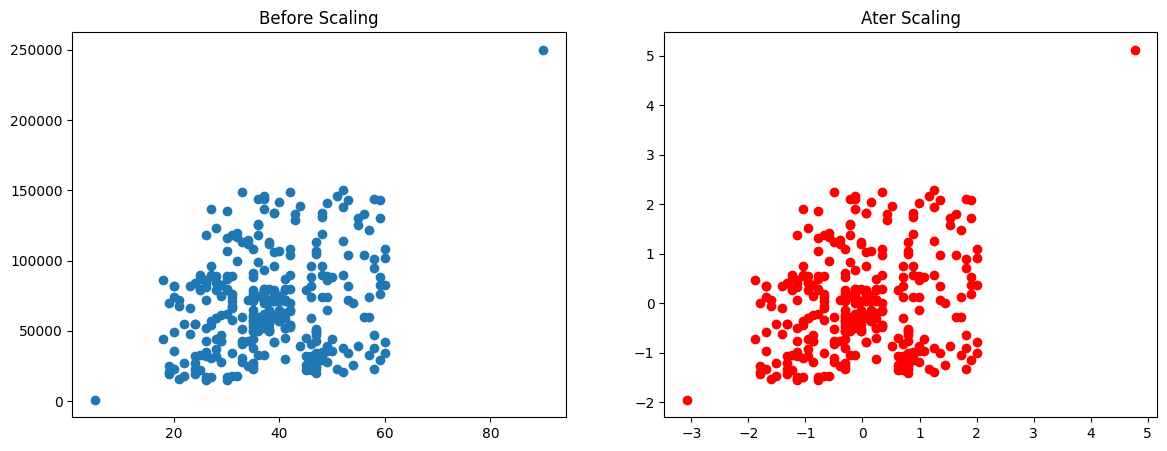

In [42]:
fig, ax = plt.subplots(ncols=2, figsize=(14,5))

ax[0].scatter(X_train['Age'], X_train['EstimatedSalary'])
ax[0].set_title('Before Scaling')

ax[1].scatter(X_train_scaled['Age'], X_train_scaled['EstimatedSalary'], color='red')
ax[1].set_title('Ater Scaling')

plt.show()

<Axes: >

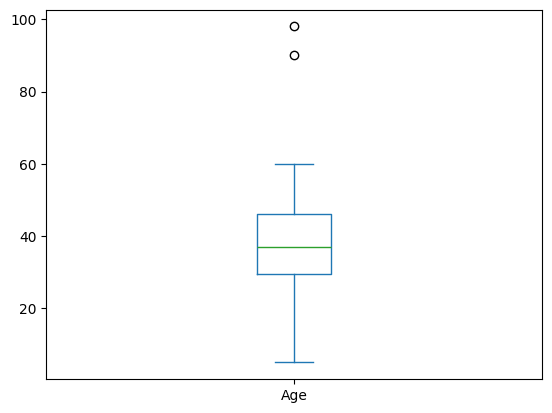

In [43]:
df['Age'].plot(kind='box')

### Implement Standardization from Scratch

This section builds a small class that follows the same two-step process as `StandardScaler`:

1. `fit()` calculates and stores the mean and standard deviation from the training data.
2. `transform()` uses those stored statistics to standardize new data.

The scaler must be fitted on the training data before transforming either the training or test data.

In [44]:
class standardization: 
    def __init__(self): 
        self.mean = None 
        self.std = None

    def fit(self, X_train): 
        self.mean = X_train.mean().values
        self.std = X_train.std(ddof=0).values

    def transform(self, df):
        scaled_df = (df - self.mean) / self.std
        return scaled_df
        

In [45]:
t = standardization()

In [46]:
t.fit(X_train)

In [47]:
t.mean

array([3.83478261e+01, 6.97236025e+04])

In [48]:
t = t.transform(X_train)
t

,Age,EstimatedSalary
190,-1.326403,0.405638
328,-0.217048,1.371685
255,1.262093,0.576117
64,1.909217,0.377225
55,-1.326403,-0.418344
...,...,...
323,0.892308,-1.128673
192,-0.864172,-0.759302
117,-0.217048,-0.503584
47,-1.049065,-0.446757


In [47]:
np.round(t.describe(), 2)

,Age,EstimatedSalary
count,280.00,280.00
mean,-0.00,-0.00
std,1.00,1.00
min,-1.92,-1.55
25%,-0.78,-0.79
50%,-0.11,-0.03
75%,0.84,0.52
max,2.08,2.22


### When Is Standardization Useful?

Standardization is commonly useful for algorithms that rely on distances, feature magnitudes, or gradient-based optimization, including

-  K-Means,
-  K-Nearest Neighbors (KNN)
-  Support Vector Machines (SVM)
-  Principal Component Analysis (PCA)
-  Neural networks
-  models trained using Gradient Descent

Tree-based models such as Decision Trees and Random Forests generally do not need feature standardization.

### Key Takeaways

- Standardization transforms each numerical feature to a scale with mean approximately 0 and standard deviation approximately 1.
- The transformation uses the training data's mean and standard deviation.
- Always split the data first, fit the scaler on training data only, and reuse it to transform test data.
- Scaling is important for many distance-based and gradient-based algorithms, but usually not necessary for tree-based models.
- Outliers can strongly affect standardization because the mean and standard deviation are sensitive to extreme values.